# Mamdani Fuzzy System: from expert rules to a number

**Goal.** Build a fuzzy system by writing rules by hand, with no training at all.

**Four steps.**
1. **Fuzzification**: turn each number into membership degrees.
2. **Rule evaluation**: `AND` is the minimum of the degrees; each conclusion is clipped by its rule strength.
3. **Aggregation**: combine all clipped conclusions with the maximum.
4. **Defuzzification**: the centroid of the combined shape is the output.


**The dataset.** *Combined Cycle Power Plant* (UCI): 9,568 hourly records. Inputs: ambient temperature `AT`, exhaust vacuum `V`,
ambient pressure `AP`, humidity `RH`. Output: electrical power `PE` in MW.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi",
    "openpyxl": "openpyxl",
    "skfuzzy": "scikit-fuzzy",
    "networkx": "networkx"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## Part A. The cooling-fan example from the slides
Inputs are a transformer's temperature and load. The output is fan speed.

In [3]:
import skfuzzy as fuzz
from skfuzzy import control as ctrl

temp = ctrl.Antecedent(np.arange(40, 121), "temp")
load = ctrl.Antecedent(np.arange(0, 121), "load")
fan = ctrl.Consequent(np.arange(0, 101), "fan")

temp["low"] = fuzz.trapmf(temp.universe, [30, 40, 60, 80])
temp["med"] = fuzz.trimf(temp.universe, [60, 80, 100])
temp["high"] = fuzz.trapmf(temp.universe, [80, 100, 120, 130])
load["light"] = fuzz.trapmf(load.universe, [-10, 0, 30, 70])
load["heavy"] = fuzz.trapmf(load.universe, [40, 90, 120, 130])
fan["slow"] = fuzz.trapmf(fan.universe, [-10, 0, 20, 50])
fan["med"] = fuzz.trimf(fan.universe, [25, 50, 75])
fan["fast"] = fuzz.trapmf(fan.universe, [50, 80, 100, 110])

fan_rules = [
    ctrl.Rule(temp["low"] & load["light"], fan["slow"]),
    ctrl.Rule(temp["low"] & load["heavy"], fan["med"]),
    ctrl.Rule(temp["med"] & load["light"], fan["med"]),
    ctrl.Rule(temp["med"] & load["heavy"], fan["fast"]),
    ctrl.Rule(temp["high"], fan["fast"]),
]
fan_system = ctrl.ControlSystemSimulation(ctrl.ControlSystem(fan_rules))
fan_system.input["temp"], fan_system.input["load"] = 88, 75
fan_system.compute()
fan_speed = fan_system.output["fan"]
print(f"Temperature 88 C, load 75 %  ->  fan speed {fan_speed:.1f} %")

Temperature 88 C, load 75 %  ->  fan speed 79.2 %


## Part B. A rule-based model of a real power plant

In [4]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "ccpp"
archive = download("https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Downloading: https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip


Saved: data\ccpp\dataset.zip (3.7 MB)
Files: ['dataset.zip', 'Folds5x2_pp.ods', 'Folds5x2_pp.xlsx', 'Readme.txt', 'Readme.txt~']


In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_excel(DATA_DIR / "CCPP" / "Folds5x2_pp.xlsx", sheet_name=0)
# The same split (seed 42, 20% test) as the linear regression notebook, so results can be compared.
train, test = train_test_split(df, test_size=0.2, random_state=SEED)
print("Train:", train.shape, "Test:", test.shape)

Train: (7654, 5) Test: (1914, 5)


## Design the membership functions and rules
We use only the two strongest inputs, `AT` and `V`. Anchors come from simple percentiles of the training data, which is the kind of information an expert would know.

Physical knowledge behind the rules: **hotter air and a higher exhaust vacuum both reduce power.**

In [6]:
q = lambda column, p: float(np.percentile(train[column], p))

at = ctrl.Antecedent(np.linspace(df.AT.min(), df.AT.max(), 200), "AT")
vac = ctrl.Antecedent(np.linspace(df.V.min(), df.V.max(), 200), "V")
pe = ctrl.Consequent(np.linspace(df.PE.min(), df.PE.max(), 300), "PE", defuzzify_method="centroid")

def three_sets(variable, column):
    """Low / Medium / High sets whose peaks sit at the 10th, 50th and 90th percentiles."""
    u = variable.universe
    low, mid, high = q(column, 10), q(column, 50), q(column, 90)
    variable["low"] = fuzz.trapmf(u, [u[0] - 1, u[0], low, mid])
    variable["med"] = fuzz.trimf(u, [low, mid, high])
    variable["high"] = fuzz.trapmf(u, [mid, high, u[-1], u[-1] + 1])

three_sets(at, "AT")
three_sets(vac, "V")

levels = dict(zip(["vlow", "low", "med", "high", "vhigh"], [q("PE", p) for p in (3, 25, 50, 75, 97)]))
points = [pe.universe[0]] + list(levels.values()) + [pe.universe[-1]]
for i, (name, center) in enumerate(levels.items()):
    pe[name] = fuzz.trimf(pe.universe, [points[i], center, points[i + 2]])

# The whole "expert knowledge" of this model fits in a small table.
rule_table = {
    ("low", "low"): "vhigh", ("low", "med"): "high", ("low", "high"): "med",
    ("med", "low"): "high",  ("med", "med"): "med",  ("med", "high"): "low",
    ("high", "low"): "med",  ("high", "med"): "low", ("high", "high"): "vlow",
}
rules = [ctrl.Rule(at[a] & vac[v], pe[out]) for (a, v), out in rule_table.items()]
system = ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules), flush_after_run=500)
print("Number of rules:", len(rules))

Number of rules: 9


## Evaluate on the test set
The system is computed sample by sample, so this cell takes a moment.

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def report(y_true, y_pred):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    return rmse, float(mean_absolute_error(y_true, y_pred)), float(r2_score(y_true, y_pred))

def mamdani_predict(AT, V):
    outputs = []
    for a, v in zip(AT, V):
        system.input["AT"], system.input["V"] = float(a), float(v)
        system.compute()
        outputs.append(system.output["PE"])
    return np.array(outputs)

y_pred = mamdani_predict(test.AT, test.V)
rmse, mae, r2 = report(test.PE, y_pred)
print(f"RMSE = {rmse:.2f} MW | MAE = {mae:.2f} MW | R2 = {r2:.4f}")

RMSE = 5.95 MW | MAE = 4.64 MW | R2 = 0.8779


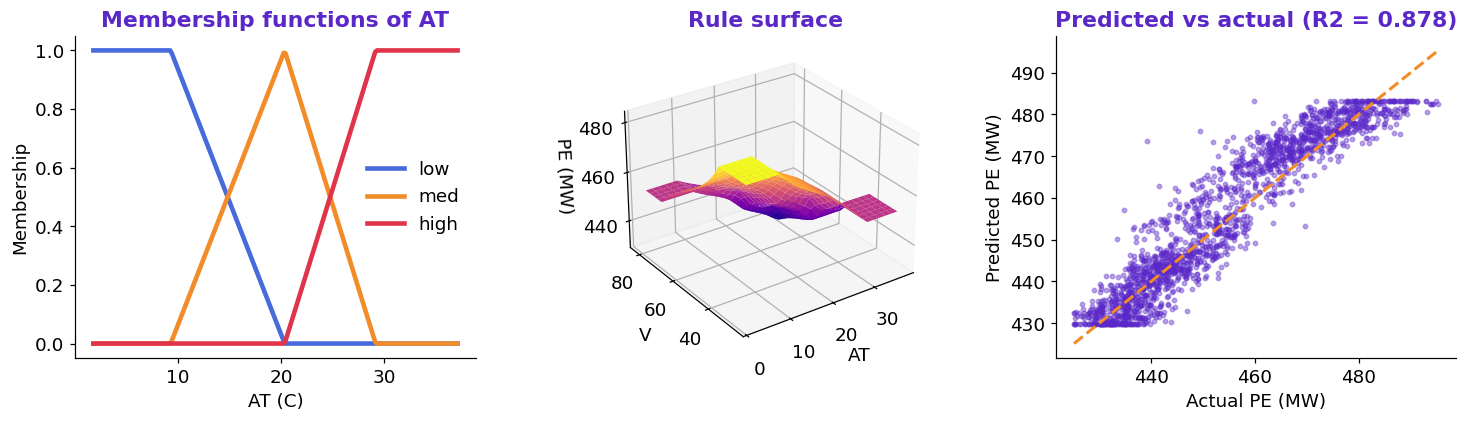

In [8]:
# Evaluate the control surface on a coarse grid.
at_grid = np.linspace(df.AT.min(), df.AT.max(), 25)
v_grid = np.linspace(df.V.min(), df.V.max(), 25)
A, B = np.meshgrid(at_grid, v_grid)
surface = mamdani_predict(A.ravel(), B.ravel()).reshape(A.shape)

fig = plt.figure(figsize=(13.5, 4))
ax1 = fig.add_subplot(1, 3, 1)
for name, color in zip(("low", "med", "high"), (BLUE, ORANGE, RED)):
    ax1.plot(at.universe, at[name].mf, color=color, lw=3, label=name)
ax1.set(title="Membership functions of AT", xlabel="AT (C)", ylabel="Membership")
ax1.legend()

ax2 = fig.add_subplot(1, 3, 2, projection="3d")
ax2.plot_surface(A, B, surface, cmap="plasma", lw=0)
ax2.set(title="Rule surface", xlabel="AT", ylabel="V", zlabel="PE (MW)")
ax2.view_init(28, -125)

ax3 = fig.add_subplot(1, 3, 3)
ax3.scatter(test.PE, y_pred, s=8, alpha=0.4, color=PURPLE)
limits = [test.PE.min(), test.PE.max()]
ax3.plot(limits, limits, "--", color=ORANGE, lw=2)
ax3.set(title=f"Predicted vs actual (R2 = {r2:.3f})", xlabel="Actual PE (MW)", ylabel="Predicted PE (MW)")
fig.tight_layout()
plt.show()

In [9]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "01_mamdani.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "Mamdani fuzzy system",
    "dataset": "Combined Cycle Power Plant (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"RMSE (MW)": round(rmse, 2), "MAE (MW)": round(mae, 2), "R2": round(r2, 4), "Rules": len(rules), "Fan example (%)": round(float(fan_speed), 1)},
}
(results_dir / "01_mamdani.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "Mamdani fuzzy system",
  "dataset": "Combined Cycle Power Plant (UCI)",
  "n_samples": 9568,
  "metrics": {
    "RMSE (MW)": 5.95,
    "MAE (MW)": 4.64,
    "R2": 0.8779,
    "Rules": 9,
    "Fan example (%)": 79.2
  }
}


## What to remember
- Nine readable rules, with no training, already give a useful model.
- Every prediction can be explained by pointing at the rules that fired.
- The next two notebooks show what happens when data is allowed to tune the system.